# How many groups are there?

K-means in twelve lines, the elbow, and the case where it confidently finds
groups that do not exist.

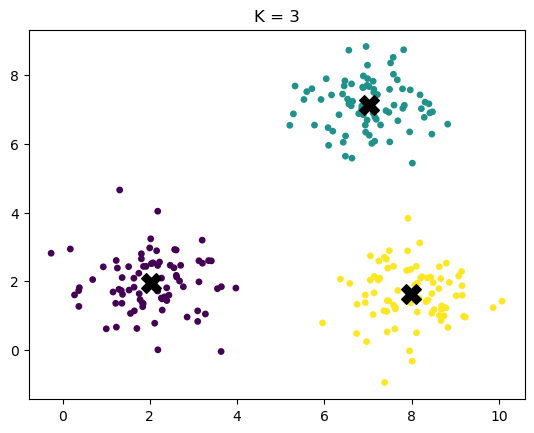

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(3)

centers_true = np.array([[2, 2], [7, 7], [8, 1.5]])
X = np.vstack([rng.normal(c, 0.8, size=(80, 2)) for c in centers_true])

def kmeans(X, K, iters=30, seed=0):
    r = np.random.default_rng(seed)
    means = X[r.choice(len(X), K, replace=False)]
    for _ in range(iters):
        labels = np.argmin(((X[:, None, :] - means[None, :, :]) ** 2).sum(axis=2), axis=1)  # assign
        means = np.array([X[labels == k].mean(axis=0) for k in range(K)])                  # update
    wss = sum(((X[labels == k] - means[k]) ** 2).sum() for k in range(K))
    return means, labels, wss

means, labels, wss = kmeans(X, 3)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=15); plt.scatter(*means.T, marker="X", s=200, c="k")
plt.title("K = 3"); plt.show()

## Choosing K: the elbow

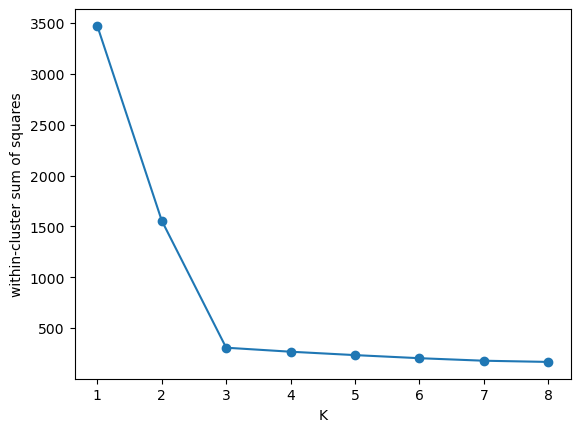

[3472, 1557, 306, 267, 233, 203, 178, 166]


In [2]:
Ks = range(1, 9)
wss = [min(kmeans(X, K, seed=s)[2] for s in range(5)) for K in Ks]
plt.plot(Ks, wss, "o-"); plt.xlabel("K"); plt.ylabel("within-cluster sum of squares"); plt.show()
print([round(w) for w in wss])

WSS always falls, and it is zero at $K = n$, so you cannot minimize it. The
elbow is where the drop stops being steep: here, 3.

## When K-means is wrong

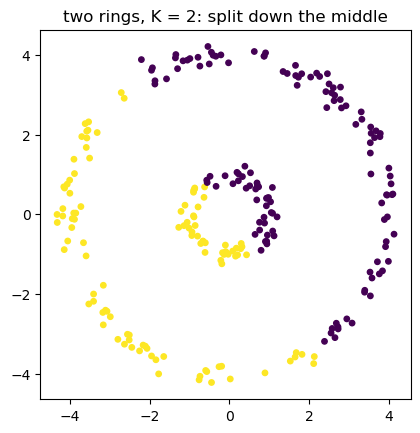

In [3]:
angles = rng.random(240) * 2 * np.pi
r = np.where(np.arange(240) < 80, 1.0, 4.0)
rings = np.column_stack([r * np.cos(angles), r * np.sin(angles)]) + rng.normal(0, 0.15, (240, 2))
_, lab, _ = kmeans(rings, 2, seed=2)
plt.scatter(rings[:, 0], rings[:, 1], c=lab, s=15); plt.gca().set_aspect("equal")
plt.title("two rings, K = 2: split down the middle"); plt.show()

K-means returned two clusters because it was asked for two. It never says "there
are no groups"; that judgment is yours.

**What we used:** unsupervised learning, K-means and the elbow method
(session 10, sections 2 and 10).